# Checking support before reweighting

## Target-Positive Source Support

Let $n_{ag}^S$ be the source count receiving treatment level $a$ in stratum $g$. The released calculation requires

$$
\pi_g^T>0\quad\Longrightarrow\quad n_{1g}^S>0\ \text{ and }\ n_{0g}^S>0.
$$

The target probability $\pi_g^T$ determines whether the stratum contributes. The counts $n_{1g}^S$ and $n_{0g}^S$ determine whether both source conditional means can be supported. This numerical rule prevents extrapolation into a target-relevant stratum that lacks one source treatment group.

### Comparing coarse partitions with fine partitions

The public panel has support under the approved three-stratum rule. Finer rules can create target-positive strata with a missing source treatment group. The support audit is therefore performed before any target effect is calculated.

#### Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("06_transportability");
using CSV, TOML, Printf
using RiskLabAI.CausalFactorAnalysis: transported_ate
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSensitivityStudy.jl"))
include(joinpath("..","support","BookTransportStudy.jl"))
using .BookTransportStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter06_random_inputs"),"transport")
captions=Dict("transport_notation"=>"Notation for finite-stratum transport.","transport_assumption_ledger"=>"Assumption ledger for finite-stratum standardization.","transport_exact_inputs"=>"Inputs for the released exact standardization calculation.","transport_exact_contributions"=>"Stratum contributions to the exact target effect.","transport_exact_check"=>"Exact standardization identity check.","transport_public_provenance"=>"Provenance of the public panel used for descriptive standardization.","transport_public_domains"=>"Source and target domains in the public county calculation.","transport_public_strata"=>"Source outcomes, support counts, and target weights by baseline-employment stratum.","transport_public_support_book"=>"Public support counts and population weights by stratum.","transport_public_contrasts_book"=>"Public source means and contrasts by stratum.","transport_public_effects"=>"Descriptive public source and target comparisons.","transport_public_decomposition"=>"Decomposition of the public source-to-target weight change.","transport_public_decomposition_book"=>"Readable decomposition of the public source-to-target weight change.","transport_public_decomposition_check"=>"Checks for the public weight-shift decomposition.","transport_public_boundaries"=>"Interpretive limits of the public standardization.","support_partition_summary"=>"Support audit as the public baseline partition becomes finer.","support_partition_summary_book"=>"Readable support audit as the public partition becomes finer.","support_primary_terciles"=>"Support audit for the approved three-stratum public calculation.","support_quartile_audit"=>"Four-stratum audit showing the first public support failure.","support_public_failure_record"=>"Recorded failure for the unsupported four-stratum public calculation.","support_target_weight_path"=>"Target-weight path from the public source mix to the public target mix.","support_target_weight_path_selected"=>"Selected points on the public target-weight path.","support_target_weight_path_book"=>"Readable points on the public target-weight path.","support_simplex_extrema"=>"Selected points on the target-weight simplex.","support_zero_mass_contract"=>"Zero-target-mass and positive-target-mass calculations.","support_invalid_input_checks"=>"Explicit input and support failures.","support_invalid_input_checks_book"=>"Plain-language input and support checks.","support_section_summary"=>"Summary of target weights and support checks.","recovery_generated_design"=>"Declared design for the generated transport experiment.","recovery_generated_contract"=>"Scope of the generated transport experiment.","recovery_domain_weights"=>"Generated source and target stratum weights.","recovery_stratum_effects"=>"Known and recovered effects in each generated stratum.","recovery_primary_check"=>"Exact known-truth recovery in the generated design.","recovery_estimate_comparison"=>"Generated estimates under correct, coarsened, and omitted modifiers.","recovery_coarse_strata"=>"Coarsened modifier calculation in the generated design.","recovery_target_mix_path"=>"Generated truth and estimates as the target composition changes.","recovery_target_mix_selected"=>"Selected points on the generated target-composition path.","recovery_target_mix_book"=>"Readable points on the generated target-composition path.","recovery_support_cases"=>"Generated support success and failure cases.","recovery_support_cases_book"=>"Plain-language generated support cases.","recovery_invalid_input_checks"=>"Generated-design input validation checks.","recovery_invalid_input_checks_book"=>"Plain-language generated-design input checks.","recovery_section_summary"=>"Summary of generated recovery and failure results.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim6-"*replace(name,"_"=>"-"))
    return nothing
end;


#### Partition rows

In [1]:
raw,counties,population_median=transport_counties()
partition_rows=[]
partition_details=Dict{Int,DataFrame}()
assignment_rows=[]
for requested_strata in 2:10
    partitioned=copy(counties)
    partitioned[!,"Partition stratum"]=transport_partition(partitioned[:,3],requested_strata)
    for row in eachrow(partitioned)
        push!(assignment_rows,(requested_strata,row[1],row["Partition stratum"]))
    end
    summary=transport_summary(partitioned,"Partition stratum")
    positive=summary[:,"Target count"].>0
    unsupported=positive .& ((summary[:,"Source control count"].==0) .| (summary[:,"Source treated count"].==0))
    detail=DataFrame("Stratum"=>summary.Stratum,"Target count"=>summary[:,"Target count"],"Source control count"=>summary[:,"Source control count"],"Source treated count"=>summary[:,"Source treated count"],"Target positive"=>positive,"Supported"=>.!unsupported)
    partition_details[requested_strata]=detail
    push!(partition_rows,(requested_strata,nrow(summary),sum(positive),sum(positive .& .!unsupported),sum(unsupported),minimum(detail[positive,"Source control count"]),minimum(detail[positive,"Source treated count"]),any(unsupported) ? "Stop" : "Pass"))
end
partition_assignments=frame(["Requested strata","County identifier","Partition stratum"],assignment_rows)
save_data(partition_assignments,paths,"support_partition_assignments")
partition_summary=frame(["Requested strata","Realized strata","Target-positive strata","Supported target strata","Unsupported target strata","Smallest source control count","Smallest source treated count","Calculation status"],partition_rows)
table(partition_summary,"support_partition_summary")
table(partition_summary[:,["Requested strata","Supported target strata","Unsupported target strata","Smallest source treated count","Calculation status"]],"support_partition_summary_book")
primary_support=copy(partition_details[3])
insertcols!(primary_support,2,"Stratum name"=>["Low","Middle","High"])
table(primary_support,"support_primary_terciles")
table(partition_details[4],"support_quartile_audit")
partitioned=copy(counties)
partitioned[!,"Partition stratum"]=transport_partition(partitioned[:,3],4)
quartile_summary=transport_summary(partitioned,"Partition stratum")
quartile_failure=transport_failure("Four-stratum target standardization",()->transported_ate(replace(quartile_summary[:,"Source treated mean"],NaN=>0.),replace(quartile_summary[:,"Source control mean"],NaN=>0.),quartile_summary[:,"Target probability"],quartile_summary[:,"Source treated count"],quartile_summary[:,"Source control count"]))
table(frame(["Check","Rejected","Message"],[quartile_failure]),"support_public_failure_record");


Row,Requested strata,Realized strata,Target-positive strata,Supported target strata,Unsupported target strata,Smallest source control count,Smallest source treated count,Calculation status
,Int64,Int64,Int64,Int64,Int64,Int64,Int64,String
1,2,2,2,2,0,22,11,Pass
2,3,3,3,3,0,5,1,Pass
3,4,4,4,3,1,2,0,Stop
4,5,5,5,4,1,0,0,Stop
5,6,6,6,5,1,0,0,Stop
6,7,7,7,5,2,0,0,Stop
7,8,8,7,5,2,0,0,Stop
8,9,9,8,6,2,0,0,Stop
9,10,10,9,6,3,0,0,Stop


Row,Requested strata,Supported target strata,Unsupported target strata,Smallest source treated count,Calculation status
,Int64,Int64,Int64,Int64,String
1,2,2,0,11,Pass
2,3,3,0,1,Pass
3,4,3,1,0,Stop
4,5,4,1,0,Stop
5,6,5,1,0,Stop
6,7,5,2,0,Stop
7,8,5,2,0,Stop
8,9,6,2,0,Stop
9,10,6,3,0,Stop


Row,Stratum,Stratum name,Target count,Source control count,Source treated count,Target positive,Supported
,Int64,String,Int64,Int64,Int64,String,String
1,0,Low,4,116,47,Pass,Pass
2,1,Middle,85,49,32,Pass,Pass
3,2,High,161,5,1,Pass,Pass


Row,Stratum,Target count,Source control count,Source treated count,Target positive,Supported
,Int64,Int64,Int64,Int64,String,String
1,0,2,90,35,Pass,Pass
2,1,31,58,34,Pass,Pass
3,2,94,20,11,Pass,Pass
4,3,123,2,0,Pass,Fail


Row,Check,Rejected,Message
,String,String,String
1,Four-stratum target standardization,Pass,ArgumentError: target-positive strata lack source treatment support


#### Finer Partitions Expose Public Support Gaps

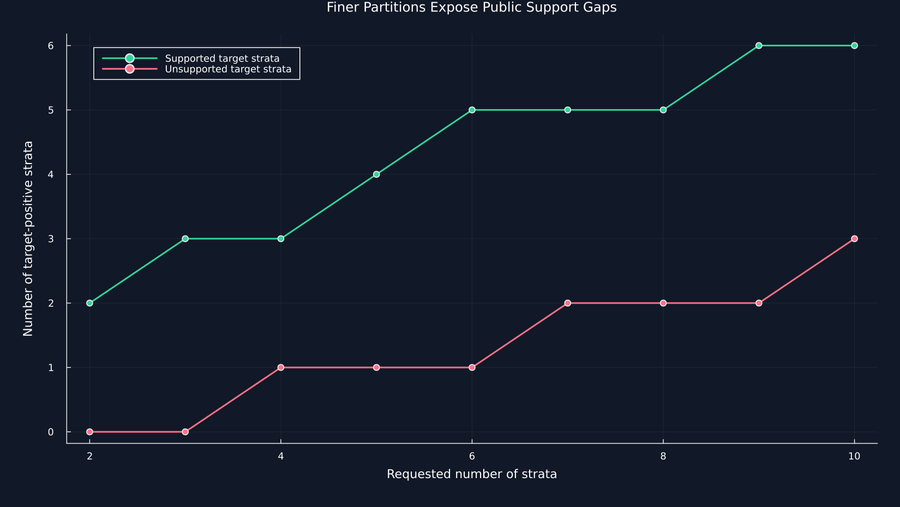

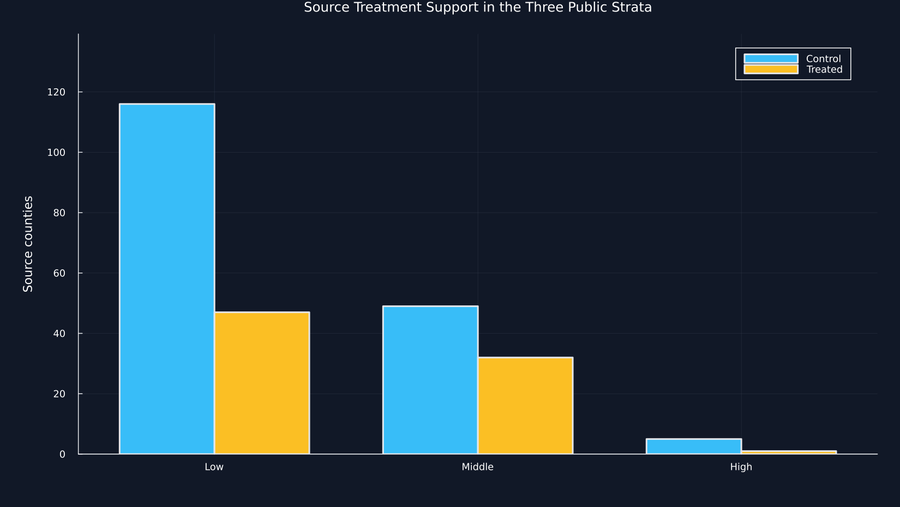

In [1]:
@assert quartile_failure[2]
save_data(partition_summary,paths,"support_partition_counts")
figure=plot(partition_summary[:,1],partition_summary[:,4];color=palette.green,marker=:circle,label="Supported target strata",xlabel="Requested number of strata",ylabel="Number of target-positive strata",title="Finer Partitions Expose Public Support Gaps",size=(1100,620),legend=:topleft)
plot!(figure,partition_summary[:,1],partition_summary[:,5];color=palette.rose,marker=:circle,label="Unsupported target strata")
save_figure(figure,paths,"support_partition_counts")
save_data(primary_support,paths,"support_primary_counts")
figure=paired_bars(primary_support[:,2],primary_support[:,4],primary_support[:,5],"Source Treatment Support in the Three Public Strata","Source counties";left_label="Control",right_label="Treated")
save_figure(figure,paths,"support_primary_counts")


## Paths Through Target Weights

Let $\pi^S$ and $\pi^T$ be the source and target weight vectors. A path between them is

$$
\pi(\lambda)=(1-\lambda)\pi^S+\lambda\pi^T,\qquad 0\leq\lambda\leq1.
$$

The value $\lambda=0$ gives the source mix, while $\lambda=1$ gives the target mix. Holding the source stratum effects fixed, the standardized effect along the path is

$$
\tau(\lambda)=\sum_{g=1}^{K}\pi_g(\lambda)\tau^S(g).
$$

Thus, $\lambda$ changes population composition, $\pi_g(\lambda)$ is the weight of stratum $g$, and $\tau(\lambda)$ is the resulting weighted contrast. The path does not test whether the source contrasts are transportable.

### A Continuous Path from Source Weights to Target Weights

Row,Target mixing weight,Low-stratum probability,Middle-stratum probability,High-stratum probability,Standardized contrast
,Float64,Float64,Float64,Float64,Float64
1,0.0,0.652,0.324,0.024,-0.035567
2,0.05,0.6202,0.3248,0.055,-0.0326584
3,0.1,0.5884,0.3256,0.086,-0.0297498
4,0.15,0.5566,0.3264,0.117,-0.0268413
5,0.2,0.5248,0.3272,0.148,-0.0239327
6,0.25,0.493,0.328,0.179,-0.0210241
7,0.3,0.4612,0.3288,0.21,-0.0181155
8,0.35,0.4294,0.3296,0.241,-0.0152069
9,0.4,0.3976,0.3304,0.272,-0.0122983


Row,Target mixing weight,Low-stratum probability,Middle-stratum probability,High-stratum probability,Standardized contrast
,Float64,Float64,Float64,Float64,Float64
1,0.0,0.652,0.324,0.024,-0.035567
2,0.25,0.493,0.328,0.179,-0.0210241
3,0.5,0.334,0.332,0.334,-0.00648115
4,0.75,0.175,0.336,0.489,0.00806178
5,1.0,0.016,0.34,0.644,0.0226047


Row,Mix,Low,Middle,High,Contrast
,Float64,Float64,Float64,Float64,Float64
1,0.0,0.652,0.324,0.024,-0.035567
2,0.25,0.493,0.328,0.179,-0.0210241
3,0.5,0.334,0.332,0.334,-0.00648115
4,0.75,0.175,0.336,0.489,0.00806178
5,1.0,0.016,0.34,0.644,0.0226047


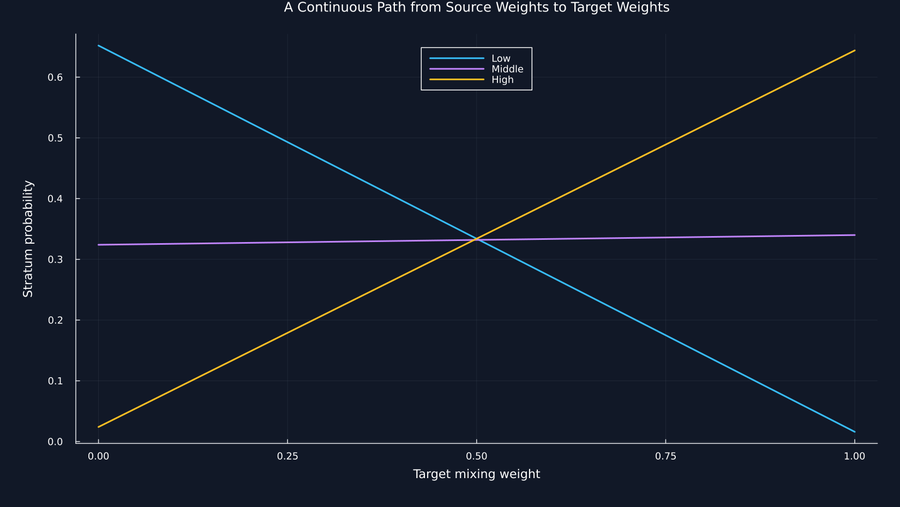

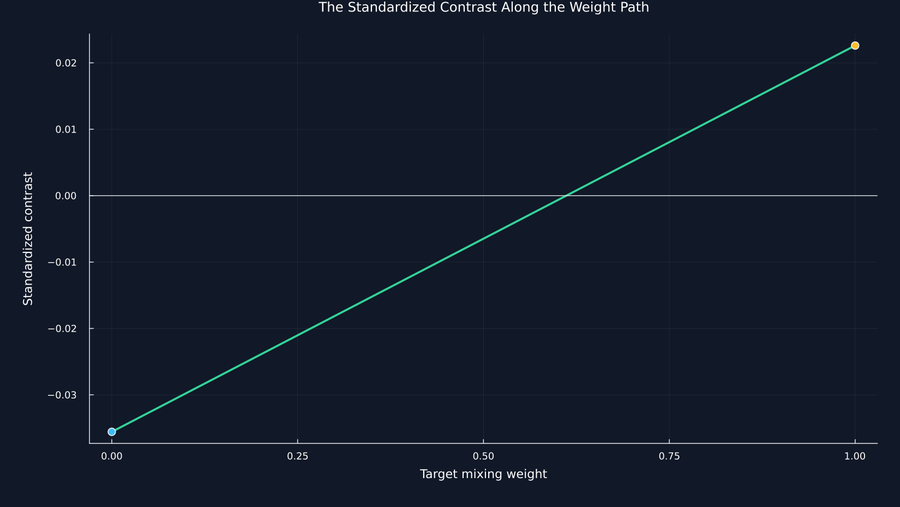

Row,Point,Low-stratum probability,Middle-stratum probability,High-stratum probability,Standardized contrast
,String,Float64,Float64,Float64,Float64
1,Minimum on grid,0.0,1.0,0.0,-0.0685717
2,Maximum on grid,0.0,0.0,1.0,0.0718774
3,Public source mix,0.652,0.324,0.024,-0.035567
4,Public target mix,0.016,0.34,0.644,0.0226047


In [2]:
public_summary=transport_summary(counties)
public_summary[!,"Stratum name"]=["Low","Middle","High"]
effects=public_summary[:,"Source contrast"]
source_weights=public_summary[:,"Source probability"]
target_weights=public_summary[:,"Target probability"]
weight_path=frame(["Target mixing weight","Low-stratum probability","Middle-stratum probability","High-stratum probability","Standardized contrast"],[(mix,weights...,dot(weights,effects)) for mix in range(0.,1.;length=21) for weights in ((1-mix).*source_weights+mix.*target_weights,)])
table(weight_path,"support_target_weight_path")
selected_path=weight_path[[1,6,11,16,21],:]
table(selected_path,"support_target_weight_path_selected")
selected_path_book=rename(copy(selected_path),["Mix","Low","Middle","High","Contrast"])
table(selected_path_book,"support_target_weight_path_book")
save_data(weight_path,paths,"support_target_weight_path")
figure=plot(weight_path[:,1],weight_path[:,2];color=palette.cyan,label="Low",xlabel="Target mixing weight",ylabel="Stratum probability",title="A Continuous Path from Source Weights to Target Weights",size=(1100,620),legend=:top)
plot!(figure,weight_path[:,1],weight_path[:,3];color="#C084FC",label="Middle")
plot!(figure,weight_path[:,1],weight_path[:,4];color=palette.amber,label="High")
save_figure(figure,paths,"support_target_weight_path")
effect_path_data=weight_path[:,["Target mixing weight","Standardized contrast"]]
save_data(effect_path_data,paths,"support_effect_path")
figure=plot(effect_path_data[:,1],effect_path_data[:,2];color=palette.green,linewidth=2.5,xlabel="Target mixing weight",ylabel="Standardized contrast",title="The Standardized Contrast Along the Weight Path",legend=false,size=(1100,620))
hline!(figure,[0.];color=palette.text,linewidth=.9,label="")
scatter!(figure,[0.,1.],effect_path_data[[1,end],2];color=[palette.cyan,palette.amber],markersize=5,label="")
save_figure(figure,paths,"support_effect_path")
simplex_rows=[]
for low in range(0.,1.;length=51)
    for middle in range(0.,1-low;length=round(Int,(1-low)*50)+1)
        high=1-low-middle
        push!(simplex_rows,(low,middle,high,low*effects[1]+middle*effects[2]+high*effects[3],middle+.5high,sqrt(3)*high/2))
    end
end
simplex=frame(["Low-stratum probability","Middle-stratum probability","High-stratum probability","Standardized contrast","Horizontal coordinate","Vertical coordinate"],simplex_rows)
save_data(simplex,paths,"support_weight_simplex")
simplex_extrema=frame(vcat(["Point"],names(simplex)[1:4]),[("Minimum on grid",Tuple(simplex[argmin(simplex[:,4]),1:4])...),("Maximum on grid",Tuple(simplex[argmax(simplex[:,4]),1:4])...),("Public source mix",source_weights...,dot(source_weights,effects)),("Public target mix",target_weights...,dot(target_weights,effects))])
table(simplex_extrema,"support_simplex_extrema");


### Standardized contrast

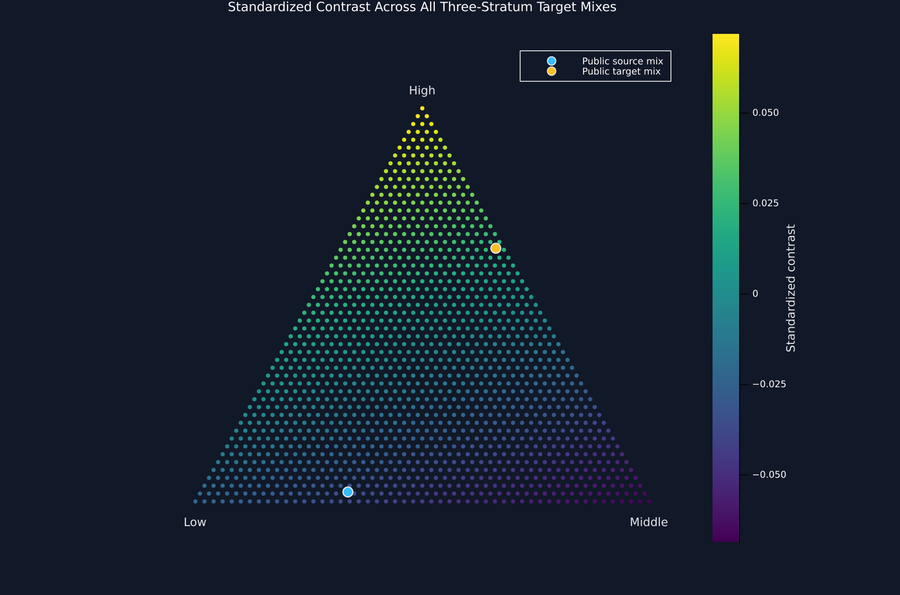

In [2]:
figure=scatter(simplex[:,5],simplex[:,6];marker_z=simplex[:,4],color=:viridis,markersize=3,markerstrokewidth=0,label="",colorbar_title="Standardized contrast",title="Standardized Contrast Across All Three-Stratum Target Mixes",aspect_ratio=:equal,axis=false,grid=false,xlims=(-.1,1.1),ylims=(-.09,1.03),size=(1150,760),legend=:topright)
for (weights,color,label) in [(source_weights,palette.cyan,"Public source mix"),(target_weights,palette.amber,"Public target mix")]
    scatter!(figure,[weights[2]+.5weights[3]],[sqrt(3)*weights[3]/2];color,markersize=7,markerstrokecolor=palette.text,markerstrokewidth=1,colorbar_entry=false,label)
end
annotate!(figure,0.,-.045,text("Low",10,palette.text))
annotate!(figure,1.,-.045,text("Middle",10,palette.text))
annotate!(figure,.5,sqrt(3)/2+.04,text("High",10,palette.text))
save_figure(figure,paths,"support_weight_simplex")


## Rejecting strata with impossible target mass

If $\pi_g^T=0$, then the stratum contribution is

$$
\pi_g^T\tau^S(g)=0.
$$

The effect $\tau^S(g)$ may be nonzero, but multiplication by the zero target weight removes its contribution. This does not permit nonfinite inputs. If the target weight becomes positive, both source treatment groups are required before the calculation can proceed.

Row,Case,Target effect,Result
,String,Float64,String
1,Zero target mass and zero source counts,1.75,Pass
2,Positive target mass with both source groups,1.6125,Pass


Row,Check,Rejected,Message
,String,String,String
1,Target probabilities do not sum to one,Pass,ArgumentError: target_probabilities must sum to one along its last dimension
2,Negative source count,Pass,ArgumentError: stratum arrays must match with nonnegative source counts
3,Mismatched stratum arrays,Pass,ArgumentError: stratum arrays must match with nonnegative source counts
4,Nonfinite supplied mean,Pass,ArgumentError: treated_means must contain finite values
5,Target-positive missing treated support,Pass,ArgumentError: target-positive strata lack source treatment support


Row,Check,Result
,String,String
1,Weights sum to one,Stopped as required
2,Source counts are nonnegative,Stopped as required
3,All stratum lists have equal length,Stopped as required
4,All supplied means are finite,Stopped as required
5,Both source groups appear where the target has mass,Stopped as required


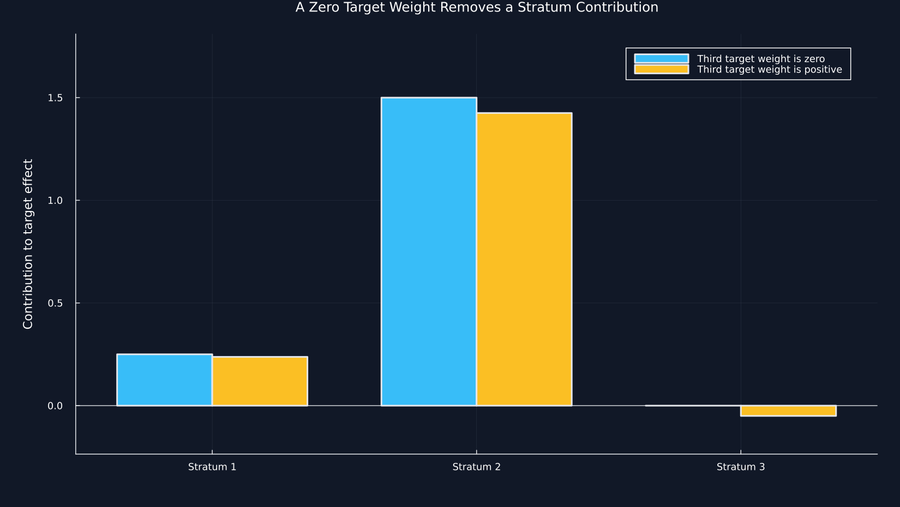

Row,Result,Value
,String,String
1,Three public strata,All target-positive strata supported
2,Four public strata,One target-positive stratum lacks treated source counties
3,Zero target mass,Zero source counts accepted when supplied means are finite
4,Positive target mass,Both source treatment groups required


In [3]:
treated_means=[2.,4.,8.]
control_means=[1.,2.,9.]
effects=treated_means-control_means
zero_weights=[.25,.75,0.]
positive_weights=[.2375,.7125,.05]
zero_counts_1=[2.,4.,0.]
zero_counts_0=[3.,7.,0.]
supported_counts_1=[2.,4.,1.]
supported_counts_0=[3.,7.,1.]
zero_value=transported_ate(treated_means,control_means,zero_weights,zero_counts_1,zero_counts_0)
positive_value=transported_ate(treated_means,control_means,positive_weights,supported_counts_1,supported_counts_0)
zero_contract=frame(["Case","Target effect","Result"],[("Zero target mass and zero source counts",zero_value,"Pass"),("Positive target mass with both source groups",positive_value,"Pass")])
table(zero_contract,"support_zero_mass_contract")
failure_cases=frame(["Check","Rejected","Message"],[transport_failure("Target probabilities do not sum to one",()->transported_ate([2,4],[1,2],[.4,.5],[2,2],[2,2])),transport_failure("Negative source count",()->transported_ate([2],[1],[1],[-1],[1])),transport_failure("Mismatched stratum arrays",()->transported_ate([2,4],[1],[.5,.5],[1,1],[1,1])),transport_failure("Nonfinite supplied mean",()->transported_ate([2,NaN],[1,2],[1,0],[1,0],[1,0])),transport_failure("Target-positive missing treated support",()->transported_ate(treated_means,control_means,positive_weights,zero_counts_1,zero_counts_0))])
table(failure_cases,"support_invalid_input_checks")
failure_cases_book = frame(["Check","Result"],[["Weights sum to one","Stopped as required"],["Source counts are nonnegative","Stopped as required"],["All stratum lists have equal length","Stopped as required"],["All supplied means are finite","Stopped as required"],["Both source groups appear where the target has mass","Stopped as required"]])
table(failure_cases_book,"support_invalid_input_checks_book")
@assert all(failure_cases.Rejected)
zero_contributions=DataFrame("Stratum"=>1:3,"Zero-mass contribution"=>zero_weights.*effects,"Positive-mass contribution"=>positive_weights.*effects)
save_data(zero_contributions,paths,"support_zero_mass_contributions")
figure=paired_bars(["Stratum 1","Stratum 2","Stratum 3"],zero_contributions[:,2],zero_contributions[:,3],"A Zero Target Weight Removes a Stratum Contribution","Contribution to target effect";left_label="Third target weight is zero",right_label="Third target weight is positive")
save_figure(figure,paths,"support_zero_mass_contributions")
support_summary = frame(["Result","Value"],[["Three public strata","All target-positive strata supported"],["Four public strata","One target-positive stratum lacks treated source counties"],["Zero target mass","Zero source counts accepted when supplied means are finite"],["Positive target mass","Both source treatment groups required"]])
table(support_summary,"support_section_summary")
